# NewsBot 2.0 · Notebook 03 – Topic Modeling & Trends
**ITAI 2373 Final Project · Mourinho Hernanto**

**Goal:** discover hidden topics with LDA and NMF, choose the number of topics with coherence, and track how topics and sentiment evolve over time.

**Course modules:** 9 (topic modelling), 6 (sentiment)

> Runs top-to-bottom in Google Colab (first cell installs everything). All logic lives in `src/` –
> this notebook demonstrates and evaluates it.

In [1]:
# ⚙️ Setup – works in Google Colab (clones the repo + installs) and locally
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content/ITAI2373-NewsBot-Final/ITAI2373-NewsBot-Final") if IN_COLAB else Path.cwd().resolve().parent
if IN_COLAB and not ROOT.exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/Haryapandhita/ITAI2373-NewsBot-Final.git",
                    "/content/ITAI2373-NewsBot-Final"], check=True)
sys.path.insert(0, str(ROOT))
from scripts.colab_setup import setup
ROOT = setup()

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
# Transformer models (summarisation, translation, multilingual embeddings) are used when
# available (Colab: Runtime -> Change runtime type -> T4 GPU recommended); otherwise
# NewsBot falls back to classical methods automatically.
USE_TRANSFORMERS = os.environ.get("NEWSBOT_USE_TRANSFORMERS", "1") == "1"
print("Transformers enabled:", USE_TRANSFORMERS)

Project root: /home/claude/NewsBot-Final/ITAI2373-NewsBot-Final  |  Colab: False


Transformers enabled: True


In [2]:
from src.data_processing.data_loader import load_all
from src.analysis.topic_modeler import TopicModeler, select_n_topics
data = load_all(); webz, bbc = data["webz"], data["bbc"]
en = pd.concat([bbc, webz[webz.language == "en"]], ignore_index=True)
en["full"] = en.title + ". " + en.text
docs = en.full.sample(4000, random_state=0).tolist()
print(len(en), "English articles; model selection on a 4,000 sample")

10793 English articles; model selection on a 4,000 sample


## 1. How many topics? LDA vs NMF
**NPMI coherence** (implemented in `topic_modeler.py`) measures whether a topic's top words really occur together (−1…1).
**Diversity** = share of unique words across topics (penalises repeated topics).

In [3]:
sel = pd.concat([select_n_topics(docs, (8, 10, 12, 15), "nmf"), select_n_topics(docs, (8, 12, 16), "lda")])
sel.sort_values("npmi", ascending=False)

20:32:12 | INFO    | src.analysis.topic_modeler | k=8 nmf npmi=0.344 diversity=0.940


20:32:15 | INFO    | src.analysis.topic_modeler | k=10 nmf npmi=0.380 diversity=0.948


20:32:19 | INFO    | src.analysis.topic_modeler | k=12 nmf npmi=0.431 diversity=0.930


20:32:23 | INFO    | src.analysis.topic_modeler | k=15 nmf npmi=0.377 diversity=0.912


20:32:47 | INFO    | src.analysis.topic_modeler | k=8 lda npmi=0.182 diversity=0.840


20:33:10 | INFO    | src.analysis.topic_modeler | k=12 lda npmi=0.225 diversity=0.770


20:33:37 | INFO    | src.analysis.topic_modeler | k=16 lda npmi=0.191 diversity=0.765


,n_topics,method,npmi,diversity,score
2,12,nmf,0.4308,0.930,1.500000
1,10,nmf,0.3804,0.948,1.415991
3,15,nmf,0.3767,0.912,0.373117
0,8,nmf,0.3445,0.940,0.777778
1,12,lda,0.2248,0.770,1.066667
2,16,lda,0.1906,0.765,0.199063
0,8,lda,0.1821,0.840,1.000000


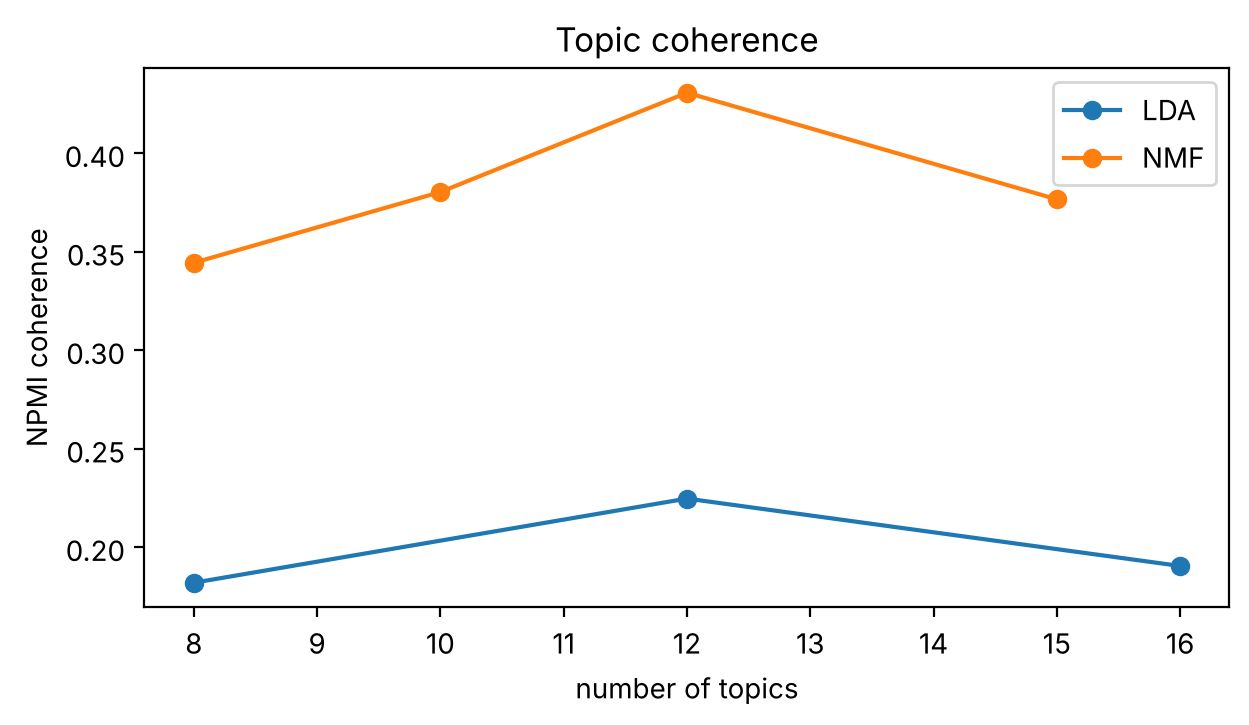

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for m, g in sel.groupby("method"): ax.plot(g.n_topics, g.npmi, marker="o", label=m.upper())
ax.set_xlabel("number of topics"); ax.set_ylabel("NPMI coherence"); ax.legend(); ax.set_title("Topic coherence"); plt.show()

## 2. Final model (NMF, k = 15)

In [5]:
tm = TopicModeler(15, "nmf")
W = tm.fit_transform(en.full)
print(f"NPMI {tm.coherence():.3f} | diversity {tm.diversity():.3f} | purity vs. category {tm.cluster_purity(en.category):.3f}")
tm.topics_table(10)

NPMI 0.432 | diversity 0.928 | purity vs. category 0.766


,topic,label,top_words,prevalence,npmi
0,6,users / up / features,"users, up, features, online, google, using, phone, mobile, software, free",0.1302,0.1902
1,4,ai / technology / solutions,"ai, technology, solutions, development, research, data, future, industry, innovation, health",0.1120,0.2518
2,1,game / season / team,"game, season, team, points, games, win, play, nba, second, night",0.1042,0.3078
3,8,court / law / state,"court, law, state, case, federal, justice, police, legal, attorney, government",0.1029,0.2799
4,9,match / cup / win,"match, cup, win, england, world, against, final, team, game, club",0.0933,0.1938
5,12,stock / price / market,"stock, price, market, trading, investors, shares, stocks, company, earnings, buy",0.0639,0.4273
6,10,film / awards / award,"film, awards, award, best, films, actor, music, star, actress, oscar",0.0622,0.3547
7,2,trump / biden / president,"trump, biden, president, donald, donald trump, harris, joe, joe biden, election, campaign",0.0585,0.5074
8,0,growth / economy / economic,"growth, economy, economic, prices, market, bank, rate, sales, oil, rates",0.0582,0.2885
9,7,israel / ukraine / military,"israel, ukraine, military, russia, war, israeli, gaza, russian, iran, nato",0.0580,0.4442


In [6]:
fig = tm.visualize_topics()
fig.show()   # interactive intertopic distance map (bubble size = prevalence)

In [7]:
lda = TopicModeler(12, "lda"); lda.fit_transform(en.full.sample(4000, random_state=1))
lda.topics_table(8)[["label", "top_words", "prevalence", "npmi"]]

,label,top_words,prevalence,npmi
0,trump / president / state,"trump, president, state, court, biden, against, law, election",0.1378,0.2365
1,up / no / city,"up, no, city, post, media, com, over, right",0.1259,0.0753
2,game / team / season,"game, team, season, games, points, win, against, up",0.1164,0.2711
3,ai / data / users,"ai, data, users, security, technology, features, design, google",0.0971,0.2381
4,company / business / market,"company, business, market, financial, services, ai, digital, global",0.0939,0.2494
5,china / economic / government,"china, economic, government, energy, economy, country, countries, world",0.0921,0.2241
6,league / arsenal / goal,"league, arsenal, goal, west, against, team, win, game",0.0848,0.2863
7,world / best / up,"world, best, up, window, film, series, br, over",0.0744,-0.0127
8,market / price / stock,"market, price, stock, growth, company, shares, investors, over",0.0579,0.3072
9,health / research / treatment,"health, research, treatment, care, medical, study, cancer, patients",0.0450,0.3961


## 3. Topics of a new article & content clustering

In [8]:
tm.get_article_topics("Nvidia shares hit a record as demand for artificial intelligence chips keeps rising, "
                      "while regulators in Brussels examine competition in the cloud market.")

[{'topic': 12, 'label': 'stock / price / market', 'weight': 0.4515},
 {'topic': 4, 'label': 'ai / technology / solutions', 'weight': 0.2678},
 {'topic': 0, 'label': 'growth / economy / economic', 'weight': 0.266}]

In [9]:
pd.crosstab(pd.Series(tm.labels_)[tm.dominant_topics()].values, en.category, normalize="index").round(2)

category,business,entertainment,politics,sport,tech
row_0,,,,,
ai / technology / solutions,0.27,0.00,0.11,0.01,0.60
arsenal / west ham / ham,0.02,0.00,0.01,0.98,0.00
brighton / tottenham / spurs,0.01,0.00,0.06,0.92,0.01
cd / ed / ce,0.15,0.01,0.29,0.39,0.16
court / law / state,0.18,0.02,0.65,0.06,0.10
film / awards / award,0.09,0.63,0.09,0.06,0.13
game / season / team,0.03,0.00,0.02,0.95,0.01
growth / economy / economic,0.81,0.00,0.10,0.00,0.08
india / modi / minister,0.14,0.00,0.74,0.04,0.08


## 4. Topic evolution 2023 → 2026 (dated Webz articles)

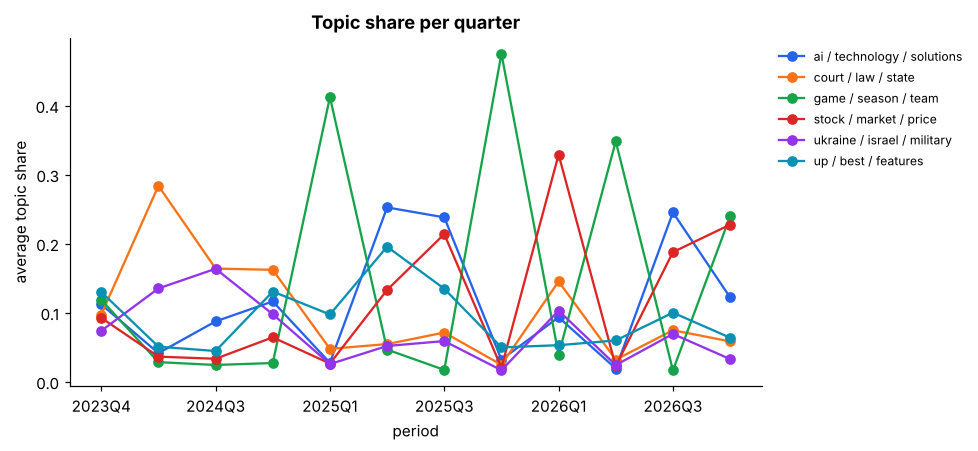

,topic,first_share,last_share,change
0,stock / market / price,0.0925,0.2274,0.1349
1,game / season / team,0.1187,0.2394,0.1207
2,india / innings / match,0.0443,0.0655,0.0212
3,ai / technology / solutions,0.1120,0.1222,0.0102
4,cd / ed / ce,0.0132,0.0178,0.0046


In [10]:
mask = en.published.notna().values
tm_dated = TopicModeler(15, "nmf"); tm_dated.fit_transform(en.loc[mask, "full"])
trends = tm_dated.track_topic_trends(en.loc[mask, "published"], freq="Q")
counts = en.loc[mask, "published"].dt.tz_convert(None).dt.to_period("Q").astype(str).value_counts()
trends = trends[trends.period.isin(counts[counts >= 100].index)]
from src.utils import visualization as viz
viz.topic_trends(trends, "Topic share per quarter"); plt.show()
TopicModeler.emerging_topics(trends)

## 5. Sentiment evolution and anomaly detection

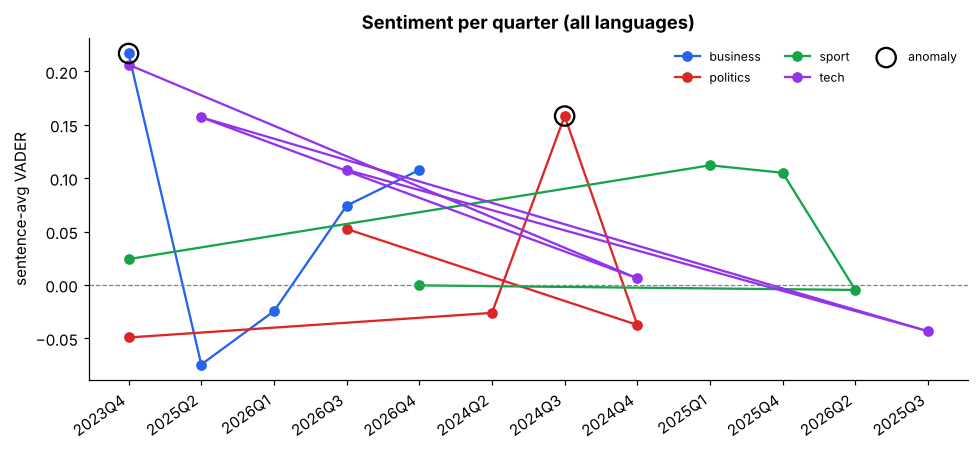

,period,category,mean_sentiment,n_articles,std,z_score,anomaly
0,2023Q4,business,0.216777,899,0.166969,1.533589,True
7,2024Q3,politics,0.158173,930,0.197500,1.778739,True


In [11]:
from src.analysis.sentiment_analyzer import SentimentAnalyzer
sa = SentimentAnalyzer()
w = webz.copy(); w["sentiment"] = sa.batch_scores((w.title + ". " + w.text).str[:6000])["sentiment"].values
tl = SentimentAnalyzer.track_over_time(w, group_col="category", freq="Q"); tl = tl[tl.n_articles >= 30]
an = SentimentAnalyzer.detect_anomalies(tl, z=1.5)
viz.timeline(an, "period", "mean_sentiment", "category", "Sentiment per quarter (all languages)", "sentence-avg VADER", anomalies=an); plt.show()
an[an.anomaly]

**Caveat:** each Webz snapshot was selected by Webz with a sentiment filter (e.g. *Politics_negative*), so part of the
quarter-to-quarter swing reflects snapshot selection, not public mood. We report it as a *capability demo* and discuss this
limitation in the technical report.

## Key takeaways
* NMF gives roughly twice the coherence of LDA on short, noisy web news, with higher diversity.
* NMF coherence is fairly flat for k = 10–20 and the best k changes with the sample (here k = 12; on the 5,000-article
  sample in `scripts/run_experiments.py` k = 20 > 10 > 15 > 12). The system uses k = 15 as a balance of coherence,
  diversity and granularity – the choice is not sharp, which we state openly.
* Topics align with but go beyond the 5 categories (AI, markets, courts, health, US politics…).
* Topic shares and sentiment can be tracked per quarter; z-score anomalies point to unusual periods worth investigating.